# Project 01 — Local Food Delivery Routing Agent

**Artificial Intelligence (AI) · 2026-27**
Degree on Computer Systems Engineering · IPCA

**Group E01**

| Name | Student number |
|------|----------------|
| Oier Zuñiga | 51240 |
| Matei Panțuru | 51235 |
| Aime-Bruce Ishimwe | 51224 |


## Contents

1. Introduction
2. Exploratory Data Analysis (EDA)
3. Modeling
4. Problem solving (informed search, local search, CSP)
5. Results analysis
6. Conclusion

# 1. Introduction

## 1.1 Context

Demand for local food is growing in the EU, but small producers face high logistics costs and price volatility. Short supply chains reduce transport emissions and food waste compared to long-distance distribution.

A digital platform that connects producers, customers and collection centers (warehouses) can make local distribution efficient and viable. The key challenge is **routing**: selecting efficient pickup-and-delivery routes under time-window constraints.

## 1.2 Purpose of the project

The goal is to develop an **intelligent routing agent** for this platform and to document the design and implementation steps.

The agent must:
- Decide the pickup-and-delivery routes of each vehicle.
- Respect the availability windows at producers and the delivery windows at customers.
- Respect the capacity of the vehicles.
- Minimize the total cost (distance/time).

## 1.3 Approach

| Technique | Use in this project |
|-----------|---------------------|
| Informed search (Greedy, A*) | Build routes using a distance/time heuristic |
| Local search (Hill climbing) | Improve an initial solution iteratively |
| Constraint Satisfaction (CSP) | Model time windows and capacity as constraints |

## 1.4 Data

We use a synthetic dataset (CSV files) covering the Braga district and Póvoa de Varzim, with producers, collection centers, vehicles, customers, orders with time windows, and a distance/time matrix between stops.

Development uses the `tiny` dataset; larger datasets share the same structure.

In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))   # so Python finds the 'src' folder

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.model import Problem, State, Stop
from src import informed, local_search, csp

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

prob = Problem.from_csv("../data_tiny")          # development dataset
prob_small = Problem.from_csv("../data_small")   # larger dataset, used to check that the code scales

In [2]:
# Greedy and A* (h1, h2) on both datasets. Needed by the local search and the comparison.
df_inf, states_inf, plans_inf = informed.run_all(prob)
df_inf_small, states_inf_small, plans_inf_small = informed.run_all(prob_small)

# 2. Exploratory Data Analysis (EDA)

We load the `tiny` dataset (development) and validate it before using it. The `small` dataset has the same structure.

In [3]:
from pathlib import Path

tables = {f.stem: pd.read_csv(f) for f in sorted(Path("../data_tiny").glob("*.csv"))}
summary = pd.DataFrame({"rows": {n: len(t) for n, t in tables.items()},
                        "columns": {n: len(t.columns) for n, t in tables.items()}})
summary

,rows,columns
collection_centers,1,5
customers,12,5
delivery_locations,5,5
distance_matrix,72,6
localities,49,6
locations,9,7
order_items,40,9
orders,12,5
producers,3,6
products,15,6


In [4]:
# Rules of the planning horizon, service and handling times (authoritative source)
tables["rules"]

,rule,value,description
0,start_date,2026-10-30,first day of the planning horizon
1,horizon_days,2,number of days
2,flow,producer>warehouse>delivery_location,every product goes through the warehouse
3,stop_service_min,10,service time at each pickup / delivery stop
4,warehouse_handling_min,15,time to unload (and to load) a vehicle at the ...
5,max_warehouse_dwell_h,24,max time a product stays in the warehouse (arr...
6,window_semantics,service_start,windows constrain when the service STARTS
7,avg_speed_kmh,45.0,used to build duration_min
8,route_factor,1.3,used to build distance_km
9,generator_seed,1,seed that produced this dataset


### 2.1 Locations and map

location_type
delivery_location    5
producer             3
collection_center    1


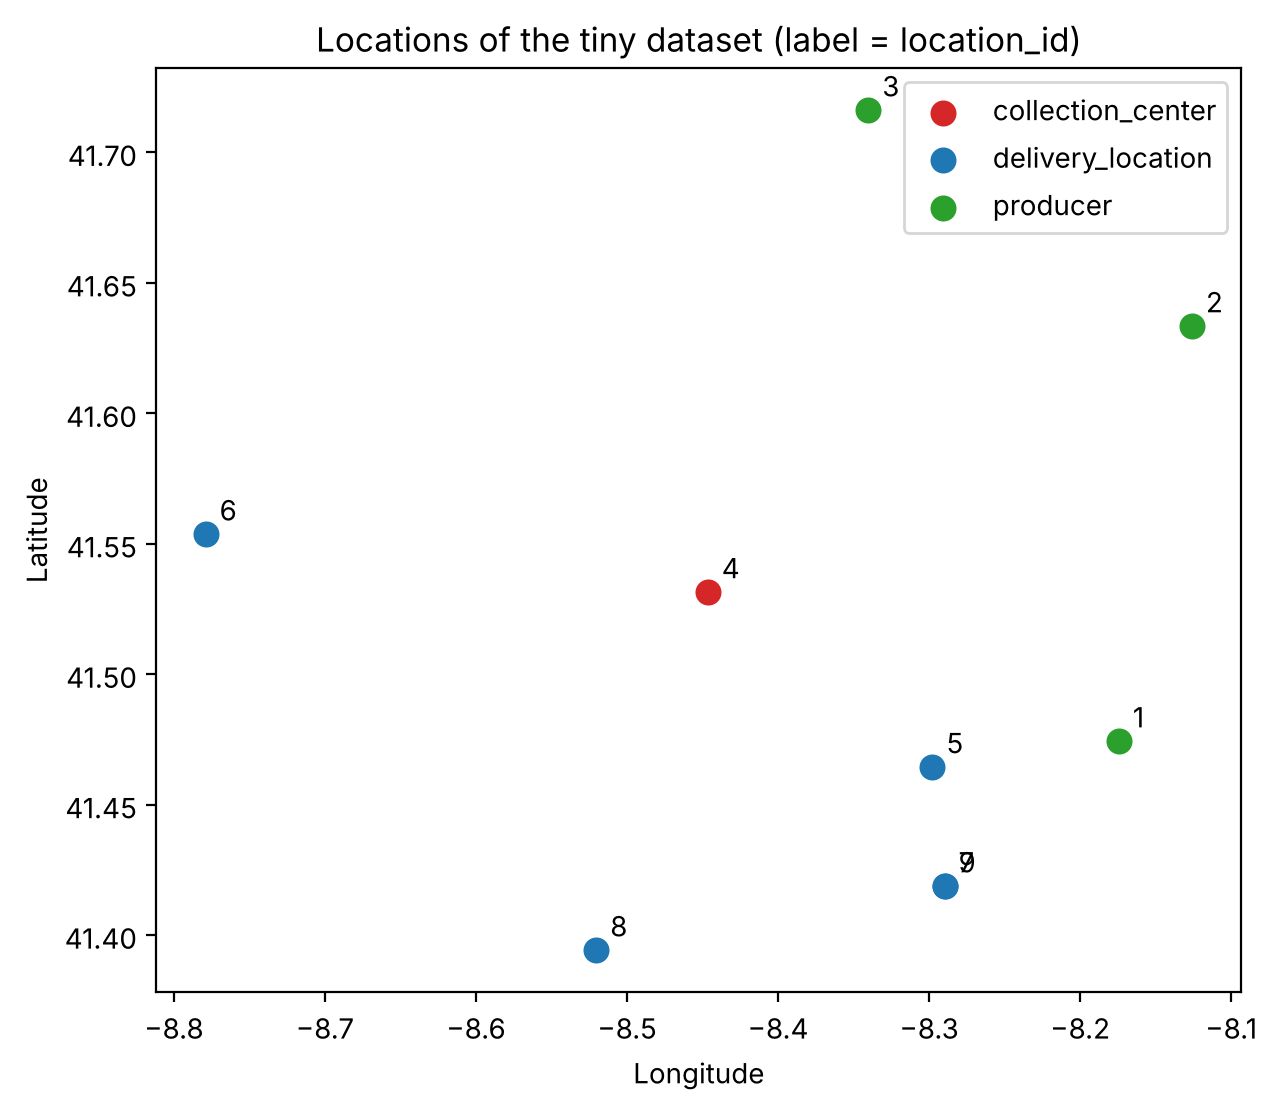

In [5]:
loc = tables["locations"]
print(loc.location_type.value_counts().to_string())

colors = {"producer": "tab:green", "collection_center": "tab:red", "delivery_location": "tab:blue"}
plt.figure(figsize=(7, 6))
for kind, group in loc.groupby("location_type"):
    plt.scatter(group.longitude, group.latitude, label=kind, color=colors.get(kind, "gray"), s=70)
    for _, r in group.iterrows():
        plt.annotate(str(r.location_id), (r.longitude, r.latitude), textcoords="offset points", xytext=(5, 5))
plt.title("Locations of the tiny dataset (label = location_id)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend()
plt.show()

### 2.2 Integrity checks

In [6]:
# Each check prints OK or raises an error, so a corrupt file cannot go unnoticed.
def check(name, condition):
    assert condition, "FAILED: " + name
    print("OK  ", name)

dist = tables["distance_matrix"]
n = len(loc)
check("location_id is unique", loc.location_id.is_unique)
check("distance matrix has every ordered pair (n*(n-1) rows)", len(dist) == n * (n - 1))
check("no self distances", (dist.origin_location_id != dist.destination_location_id).all())
check("no negative distances or durations", (dist.distance_km >= 0).all() and (dist.duration_min >= 0).all())

# A zero distance is only valid when both locations have the same coordinates
coords = loc.set_index("location_id")[["latitude", "longitude"]]
zero = dist[dist.distance_km == 0]
same_place = [(coords.loc[a] == coords.loc[b]).all() for a, b in zip(zero.origin_location_id, zero.destination_location_id)]
check("zero distances only between locations with identical coordinates (%d pairs)" % len(zero), all(same_place))

items, orders = tables["order_items"], tables["orders"]
check("every item belongs to an existing order", items.order_id.isin(orders.order_id).all())
check("every item has an existing product", items.product_id.isin(tables["products"].product_id).all())
check("every order goes to an existing delivery location", orders.delivery_location_id.isin(tables["delivery_locations"].delivery_location_id).all())
check("pickup windows are valid (end > start)", (pd.to_datetime(items.availability_end) > pd.to_datetime(items.availability_start)).all())
check("delivery windows are valid (end > start)", (pd.to_datetime(items.delivery_end) > pd.to_datetime(items.delivery_start)).all())

# Speed implied by the matrix, to compare it with the vehicle speed
speed = (dist.distance_km / (dist.duration_min / 60)).dropna()
print(f"\nImplied speed in the matrix: min {speed.min():.1f}, max {speed.max():.1f} km/h | vehicle speed: {tables['vehicles'].avg_speed_kmh.tolist()} km/h")

OK   location_id is unique
OK   distance matrix has every ordered pair (n*(n-1) rows)
OK   no self distances
OK   no negative distances or durations
OK   zero distances only between locations with identical coordinates (2 pairs)
OK   every item belongs to an existing order
OK   every item has an existing product
OK   every order goes to an existing delivery location
OK   pickup windows are valid (end > start)
OK   delivery windows are valid (end > start)

Implied speed in the matrix: min 44.9, max 45.1 km/h | vehicle speed: [45.0, 45.0] km/h


### 2.3 Demand versus capacity

In [7]:
rows = []
for o in sorted(prob.order_items):
    rows.append({"order_id": o, "items": len(prob.order_items[o]), "weight_kg": round(prob.order_weight(o), 1),
                 "pickup_day": prob.order_pickup_day(o), "delivery_day": prob.order_delivery_day(o)})
order_table = pd.DataFrame(rows)
display(order_table)

print("Vehicles:", [(v.vehicle_id, v.capacity_kg, "refrigerated" if v.refrigerated else "normal") for v in prob.vehicles])
print("Total weight of all orders: %.1f kg" % order_table.weight_kg.sum())
print("Heaviest order: %.1f kg" % order_table.weight_kg.max())

,order_id,items,weight_kg,pickup_day,delivery_day
0,1,4,22.0,2026-10-31,2026-10-31
1,2,2,6.8,2026-10-30,2026-10-31
2,3,4,21.6,2026-10-31,2026-10-31
3,4,3,26.3,2026-10-30,2026-10-30
4,5,2,9.3,2026-10-31,2026-10-31
5,6,2,16.7,2026-10-31,2026-10-31
6,7,4,33.5,2026-10-31,2026-10-31
7,8,3,18.8,2026-10-30,2026-10-31
8,9,5,36.7,2026-10-30,2026-10-31
9,10,2,9.2,2026-10-30,2026-10-30


Vehicles: [(1, 150.0, 'refrigerated'), (2, 200.0, 'normal')]
Total weight of all orders: 270.0 kg
Heaviest order: 51.1 kg


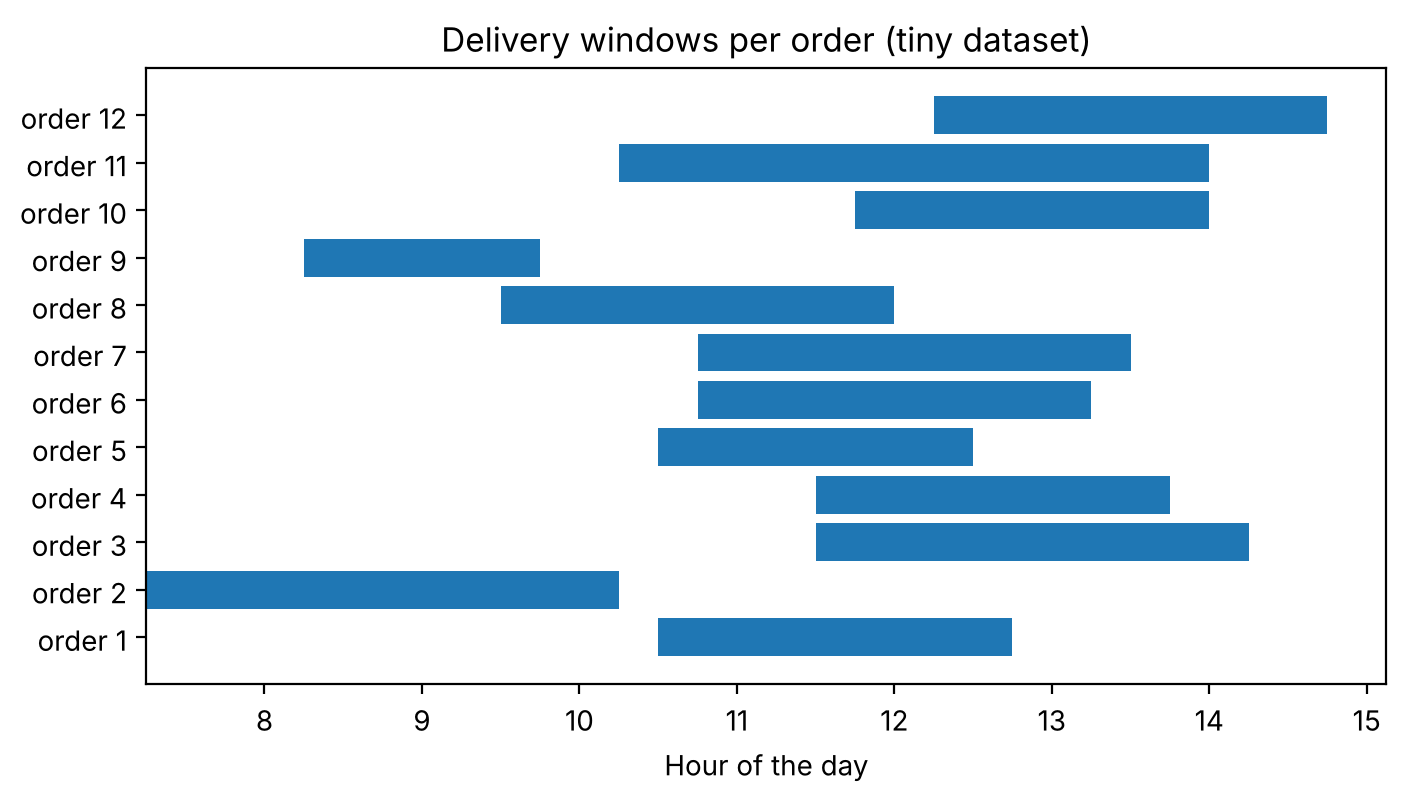

In [8]:
# Delivery window of every order (intersection of its items' windows)
plt.figure(figsize=(8, 4))
for k, o in enumerate(sorted(prob.order_items)):
    start, end = prob.delivery_window(prob.order_items[o])
    plt.barh(k, (end - start) / 60, left=start / 60 % 24, color="tab:blue")
plt.yticks(range(len(prob.order_items)), ["order %d" % o for o in sorted(prob.order_items)])
plt.xlabel("Hour of the day")
plt.title("Delivery windows per order (tiny dataset)")
plt.show()

# 3. Modeling

## 3.1 Decisions used in the implementation

Several points of the brief were left open. The values below come from `rules.csv` when it defines them; the remaining ones are **our own implementation decisions** (marked *ours*) and must be confirmed with the lecturer.

| Topic | Decision | Source |
|---|---|---|
| Time | Minutes since `start_date` 00:00 | ours |
| Waiting | A vehicle that arrives before a window opens waits | ours |
| Time windows | The *service start* must be inside the window | ours |
| Service time | Once per stop (not per item); see `service_min` below | `rules.csv` |
| Warehouse handling | Unloading and loading take `handling_min` each | `rules.csv` |
| Warehouse dwell | An item stays at most `max_dwell_min` in the warehouse | `rules.csv` |
| Flow | producer > warehouse > delivery location | `rules.csv` |
| Producer visit | One visit per producer and day, inside the intersection of the windows of its items | ours |
| End of the route | Every vehicle returns to the collection center | ours |
| Trips | Per vehicle and day: deliver stored orders, collect, deliver the new orders | ours |
| Refrigeration | Stored in the data, but there is no product rule, so it is a soft preference in the CSP only | ours |

In [9]:
print("service_min      :", prob.service_min)
print("handling_min     :", prob.handling_min)
print("max_dwell_min    :", prob.max_dwell_min)
print("depot location_id:", prob.depot_loc)

service_min      : 10.0
handling_min     : 15.0
max_dwell_min    : 1440.0
depot location_id: 4


## 3.2 State and cost

A **state** is a `State(routes)`: for every vehicle a list of `Stop(location_id, action, items)` with the actions `pickup`, `unload`, `load`, `deliver` and `return`. The **cost** is the total distance in km (`Problem.calculate_cost`). `Problem.plan_to_state` turns a plan (visiting order per vehicle and day) into a state.

## 3.3 Feasibility checker: tests with hand-made routes

The checker (`is_feasible`, `check_time`, `is_feasible_full`) must reject wrong routes, not only accept good ones.

In [10]:
import copy

df_model, states_model, plans_model = informed.run_all(prob)
good_plan = plans_model[("astar", "h1")]
good = prob.plan_to_state(good_plan)

# Test 1: the plan found by A* is feasible
print("Test 1 (A* plan)             :", prob.is_feasible_full(good))
assert prob.is_feasible_full(good)

# Test 2: an item is delivered without being picked up (flow violation)
no_flow = State({1: [Stop(prob.depot_loc, "load", (1,)), Stop(7, "deliver", (1,)), Stop(prob.depot_loc, "return", ())]})
print("Test 2 (no pickup)           :", prob.is_feasible(no_flow, check_complete=False))
assert not prob.is_feasible(no_flow, check_complete=False)

# Test 3: all the work of vehicle 2 on vehicle 1 (150 kg) breaks the capacity
overloaded = copy.deepcopy(good_plan)
for day in overloaded:
    for kind in ("collect", "deliver"):
        overloaded[day][kind][1] = overloaded[day][kind][1] + overloaded[day][kind][2]
        overloaded[day][kind][2] = []
print("Test 3 (overloaded vehicle 1):", prob.is_feasible(prob.plan_to_state(overloaded), check_capacity=True))
assert not prob.is_feasible(prob.plan_to_state(overloaded), check_capacity=True)

# Test 4: reversing the delivery order of a vehicle makes it arrive after a window closes
late = copy.deepcopy(good_plan)
day = sorted(late)[-1]
late[day]["deliver"][1] = late[day]["deliver"][1][::-1]
state_late = prob.plan_to_state(late)
print("Test 4 (reversed deliveries) :", prob.check_time(state_late))
print("   violation:", prob.simulate(state_late)[1][0])
assert not prob.check_time(state_late)

Test 1 (A* plan)             : True
Test 2 (no pickup)           : False
Test 3 (overloaded vehicle 1): False
Test 4 (reversed deliveries) : False
   violation: vehicle 1, stop 9 (deliver at 8): starts 31 10:28 after the window closes 31 10:15


In [11]:
# Readable schedule of the A* solution (day 30 = first day, 31 = second day)
prob.route_table(good).head(15)

,vehicle,stop,action,location,arrival,service_start,window,items
0,1,1,pickup,3,30 00:38,30 08:00,30 08:00 - 30 09:45,"[6, 11, 22, 24, 26, 29, 35]"
1,1,2,unload,4,30 08:48,30 08:48,,"[6, 11, 22, 24, 26, 29, 35]"
2,2,1,pickup,1,30 00:40,30 09:30,30 09:30 - 30 09:45,"[5, 13, 25, 31, 32, 34, 37, 40]"
3,2,2,pickup,2,30 10:11,30 10:11,30 09:00 - 30 10:30,"[12, 23, 27, 28, 30, 33, 36, 38, 39]"
4,2,3,unload,4,30 11:11,30 11:11,,"[5, 13, 25, 31, 32, 34, 37, 40, 12, 23, 27, 28..."
5,1,3,load,4,30 09:03,30 11:26,,"[36, 37, 38, 39, 40, 32, 33, 34, 35]"
6,1,4,deliver,6,30 12:29,30 12:29,30 12:15 - 30 14:45,"[36, 37, 38, 39, 40]"
7,1,5,deliver,5,30 13:51,30 13:51,30 10:15 - 30 14:00,"[32, 33, 34, 35]"
8,1,6,return,4,30 14:26,30 14:26,,[]
9,2,4,load,4,30 11:26,30 11:26,,"[30, 31, 11, 12, 13]"


# 4. Problem Solving

## 4.1 Informed search: Greedy best-first and A*

**Goal.** Build the visiting order of every vehicle trip with informed search and compare Greedy best-first with A* using two heuristics, counting the expanded nodes.

**Problem formulation (one trip of one vehicle).** Every route is split into *legs* that start and end at the collection center: a *collection leg* (center > producers > center) and a *delivery leg* (center > customers > center).

| Element | Definition |
|---|---|
| State | `(current location, set of stops still to visit)` and the clock (kept in the node) |
| Initial state | At the center, all stops pending |
| Actions | Go to one of the pending stops (wait if the window is not open yet) |
| Transition | Move, update clock (travel + wait + service), remove the stop from the pending set |
| Goal test | No pending stops and the vehicle is back at the center |
| Step cost | Distance in km of the move |
| Pruning | A branch is discarded if the window of a stop has already closed |

**Heuristics** (remaining cost to visit the pending stops and return to the center):

* `h1` = distance to the *nearest* pending stop (or to the center if none is left).
* `h2` = for every pending stop, the cheapest incoming edge, plus the cheapest edge back to the center; summed.

Both are **admissible**: every pending stop must be entered by some edge, which costs at least its cheapest incoming edge, and `h1` is at most one of those terms. They never overestimate, so A* returns the optimal order of a leg. Greedy uses only `f = h`, A* uses `f = g + h`. We do not prove consistency. To avoid re-expanding states, the search keeps, for every state, the best (cost, time) found so far and discards a node that is not better in both.

In [12]:
df_inf

,algorithm,heuristic,cost_km,expanded_nodes,generated_nodes,seconds,status,feasible
0,greedy,h1,724.28,46,54,0.0006,solved,True
1,greedy,h2,744.59,30,39,0.0005,solved,True
2,astar,h1,724.28,49,57,0.0025,solved,True
3,astar,h2,724.28,40,52,0.0006,solved,True


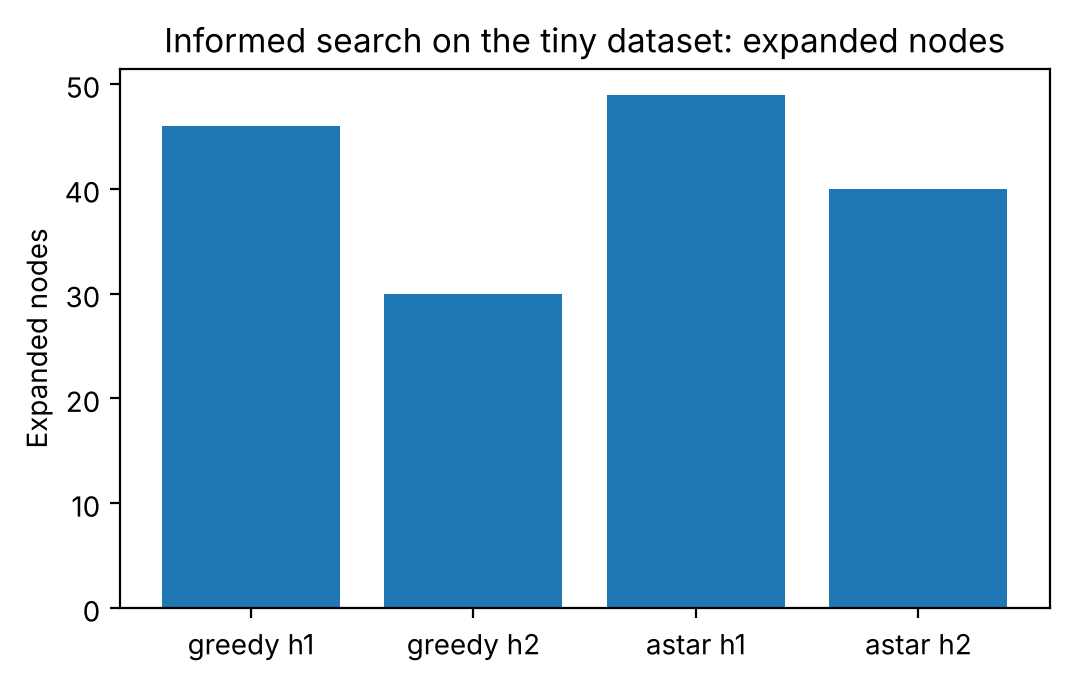

In [13]:
# Expanded nodes of each algorithm (tiny dataset)
labels = df_inf.algorithm + " " + df_inf.heuristic
plt.figure(figsize=(6, 3.5))
plt.bar(labels, df_inf.expanded_nodes, color="tab:blue")
plt.ylabel("Expanded nodes")
plt.title("Informed search on the tiny dataset: expanded nodes")
plt.show()

**Check: is the order found by A* optimal?** For every list of stops of the A* plan we try all the orderings (`itertools.permutations`) with the other lists fixed and keep the cheapest feasible one.

In [14]:
import copy, itertools

plan = plans_inf[("astar", "h2")]
plan_cost, _ = local_search.evaluate(prob, plan)
rows = []
for day in plan:
    for kind in ("collect", "deliver"):
        for vid, stops in plan[day][kind].items():
            if len(stops) < 2:
                continue
            best = None
            for order in itertools.permutations(stops):
                test = copy.deepcopy(plan)
                test[day][kind][vid] = list(order)
                cost, ok = local_search.evaluate(prob, test)
                if ok and (best is None or cost < best):
                    best = cost
            rows.append({"day": str(day), "list": kind, "vehicle": vid, "stops": len(stops),
                         "A* plan (km)": round(plan_cost, 2), "best ordering (km)": round(best, 2)})
brute = pd.DataFrame(rows)
print("Any ordering cheaper than the A* plan:", (brute["best ordering (km)"] < brute["A* plan (km)"] - 1e-6).any())
brute

Any ordering cheaper than the A* plan: False


,day,list,vehicle,stops,A* plan (km),best ordering (km)
0,2026-10-30,collect,2,2,724.28,724.28
1,2026-10-30,deliver,1,2,724.28,724.28
2,2026-10-30,deliver,2,2,724.28,724.28
3,2026-10-31,collect,2,3,724.28,724.28
4,2026-10-31,deliver,1,5,724.28,724.28
5,2026-10-31,deliver,2,3,724.28,724.28


In [15]:
# Schedule found by A* with h2 (tiny)
prob.route_table(states_inf[("astar", "h2")])

,vehicle,stop,action,location,arrival,service_start,window,items
0,1,1,pickup,3,30 00:38,30 08:00,30 08:00 - 30 09:45,"[6, 11, 22, 24, 26, 29, 35]"
1,1,2,unload,4,30 08:48,30 08:48,,"[6, 11, 22, 24, 26, 29, 35]"
2,2,1,pickup,1,30 00:40,30 09:30,30 09:30 - 30 09:45,"[5, 13, 25, 31, 32, 34, 37, 40]"
3,2,2,pickup,2,30 10:11,30 10:11,30 09:00 - 30 10:30,"[12, 23, 27, 28, 30, 33, 36, 38, 39]"
4,2,3,unload,4,30 11:11,30 11:11,,"[5, 13, 25, 31, 32, 34, 37, 40, 12, 23, 27, 28..."
5,1,3,load,4,30 09:03,30 11:26,,"[36, 37, 38, 39, 40, 32, 33, 34, 35]"
6,1,4,deliver,6,30 12:29,30 12:29,30 12:15 - 30 14:45,"[36, 37, 38, 39, 40]"
7,1,5,deliver,5,30 13:51,30 13:51,30 10:15 - 30 14:00,"[32, 33, 34, 35]"
8,1,6,return,4,30 14:26,30 14:26,,[]
9,2,4,load,4,30 11:26,30 11:26,,"[30, 31, 11, 12, 13]"


In [16]:
# The same algorithms on the small dataset
df_inf_small

,algorithm,heuristic,cost_km,expanded_nodes,generated_nodes,seconds,status,feasible
0,greedy,h1,1090.63,762,1489,0.0067,solved,True
1,greedy,h2,1131.96,149,218,0.0016,solved,True
2,astar,h1,1031.75,590,1346,0.0055,solved,True
3,astar,h2,1031.75,453,1233,0.0046,solved,True


### Observations (executed results)

* **Tiny.** Greedy h1, A* h1 and A* h2 all return **724.28 km**. The brute-force check above finds no cheaper ordering of any list, so these routes are optimal *for the vehicle split used*. Greedy h2 returns 744.59 km (+2.8 %).
* **Expanded nodes (tiny).** Greedy h1 46, Greedy h2 30, A* h1 49, A* h2 40. `h2` is better informed than `h1`: A* expands 18 % fewer nodes with it (40 vs 49).
* **Small.** A* finds 1031.75 km with both heuristics against 1090.63 km for Greedy h1 (-5.4 %). Expanded nodes: Greedy h1 762, A* h1 590, A* h2 453 (-23 % against h1), Greedy h2 149.
* Greedy with `h2` is the cheapest to run but gives the worst routes: with `f = h` it ignores the distance already travelled. A* pays more nodes and returns better routes, as expected.
* **Limits.** The legs of the tiny dataset have at most 5 stops, so the differences are small and all times are below a millisecond. The split of the items between the vehicles is decided *before* the search (first fit with random restarts, fixed seed) and is not optimised here; this is why local search improves the solutions so much later.

## 4.2 Local search: Hill-Climbing

**Initial solution:** the plan found by Greedy (h1). A solution is a plan: the visiting order of every collection and delivery list of every vehicle and day. The **neighbourhood** has four moves, as required by the brief:

* *relocate*: move a stop to another position of the same vehicle,
* *swap*: exchange two stops of the same vehicle,
* *2-opt*: reverse a segment of consecutive stops,
* *move*: move a stop to another vehicle.

Each iteration evaluates **all** the neighbours, discards the infeasible ones (flow, capacity, windows, dwell) and moves to the best one (steepest descent of the cost, i.e. steepest-ascent hill-climbing on `-cost`). It stops at a **local optimum** (no neighbour is better). A **plateau** is a set of neighbours with the same cost; with `max_sideways > 0` the search may cross it with equal-cost moves, never returning to a plan already visited. The moves 2-opt, swap and relocate are our implementation choices; the lecture slides show hill-climbing on the 8-queens problem only.

In [17]:
start_plan = plans_inf[("greedy", "h1")]
start_cost = prob.calculate_cost(prob.plan_to_state(start_plan))

best_plan, hist = local_search.hill_climbing(prob, start_plan, max_sideways=0)
best_plan_sw, hist_sw = local_search.hill_climbing(prob, start_plan, max_sideways=10)
hc_tiny = pd.DataFrame(hist)
hc_tiny_sw = pd.DataFrame(hist_sw)

print("Start (Greedy h1): %.2f km" % start_cost)
print("Hill-Climbing    : %.2f km in %d iterations (%.2f s)" % (hc_tiny.cost_km.iloc[-1], len(hc_tiny) - 1, hist[0]["seconds"]))
print("With sideways    : %.2f km in %d iterations (%.2f s)" % (hc_tiny_sw.cost_km.iloc[-1], len(hc_tiny_sw) - 1, hist_sw[0]["seconds"]))
print("Final plan feasible:", prob.is_feasible_full(prob.plan_to_state(best_plan)))
hc_tiny[["iteration", "move", "cost_km", "neighbours"]]

Start (Greedy h1): 724.28 km
Hill-Climbing    : 580.90 km in 5 iterations (0.46 s)
With sideways    : 580.90 km in 10 iterations (0.82 s)
Final plan feasible: True


,iteration,move,cost_km,neighbours
0,0,start,724.28,0
1,1,move,683.61,125
2,2,move,649.19,127
3,3,move,627.96,129
4,4,move,616.56,134
5,5,move,580.90,132


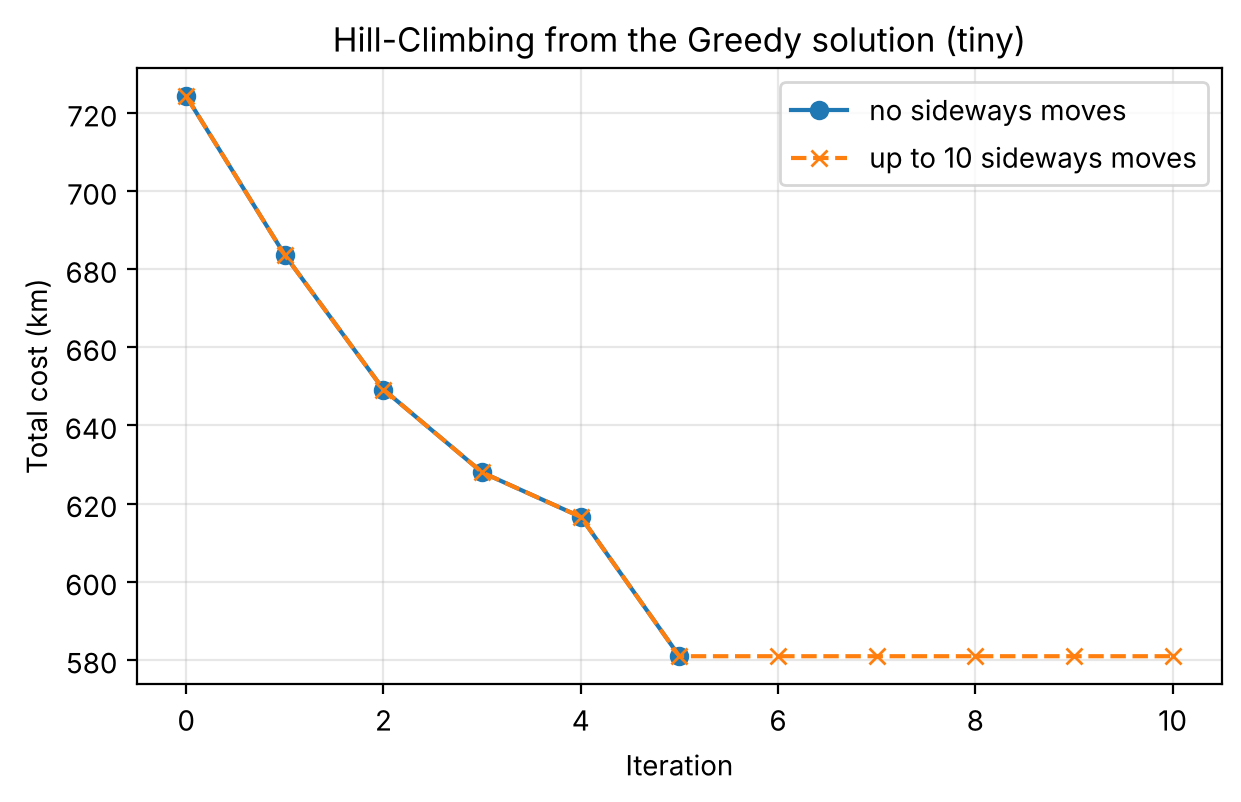

In [18]:
plt.figure(figsize=(7, 4))
plt.plot(hc_tiny.iteration, hc_tiny.cost_km, marker="o", label="no sideways moves")
plt.plot(hc_tiny_sw.iteration, hc_tiny_sw.cost_km, marker="x", linestyle="--", label="up to 10 sideways moves")
plt.xlabel("Iteration")
plt.ylabel("Total cost (km)")
plt.title("Hill-Climbing from the Greedy solution (tiny)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Start (Greedy h1): 1090.63 km
Hill-Climbing    : 785.50 km in 11 iterations (8.7 s)
Final plan feasible: True


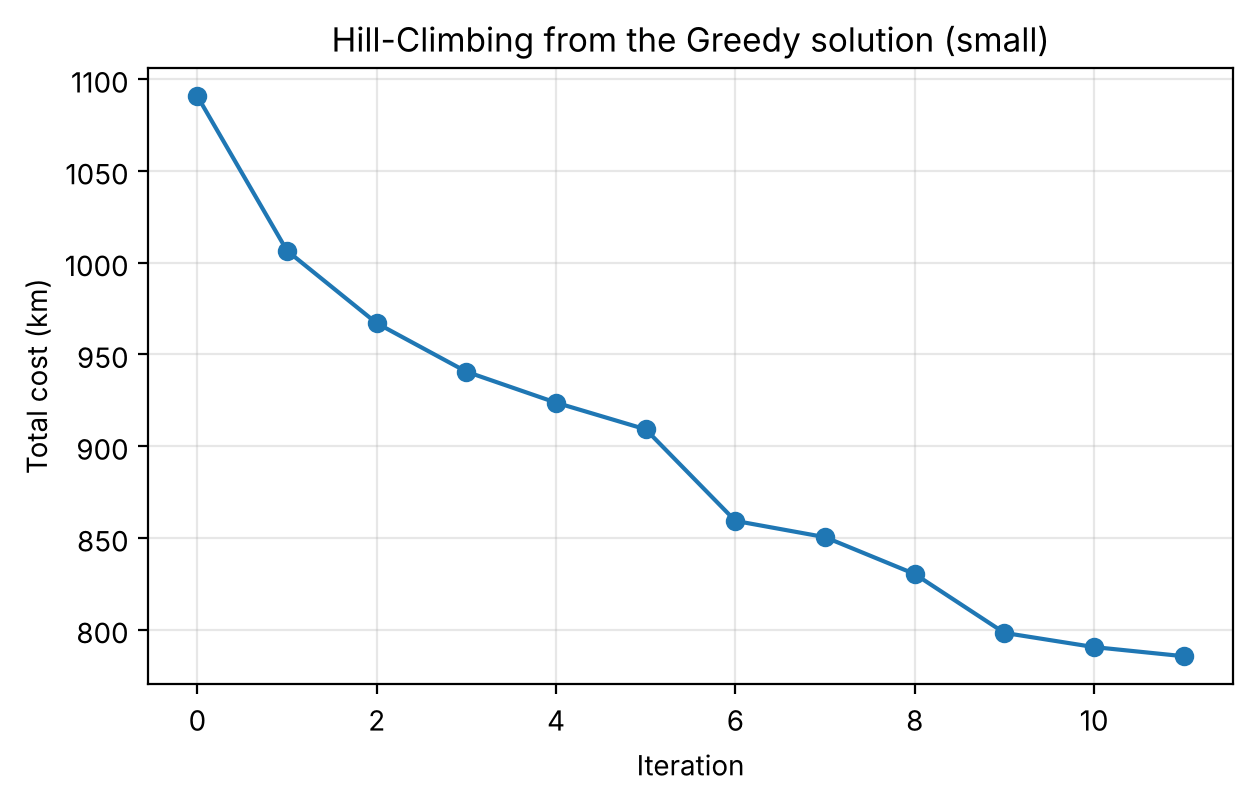

,iteration,move,cost_km,neighbours
0,0,start,1090.63,0
1,1,move,1006.44,622
2,2,move,966.95,623
3,3,move,940.53,643
4,4,move,923.65,667
5,5,relocate,909.12,673
6,6,move,859.24,671
7,7,2-opt,850.37,682
8,8,move,830.29,682
9,9,move,798.22,710


In [19]:
# Same experiment on the small dataset (starts from its own Greedy solution)
start_small = plans_inf_small[("greedy", "h1")]
best_small, hist_small = local_search.hill_climbing(prob_small, start_small)
hc_small = pd.DataFrame(hist_small)

print("Start (Greedy h1): %.2f km" % hc_small.cost_km.iloc[0])
print("Hill-Climbing    : %.2f km in %d iterations (%.1f s)" % (hc_small.cost_km.iloc[-1], len(hc_small) - 1, hist_small[0]["seconds"]))
print("Final plan feasible:", prob_small.is_feasible_full(prob_small.plan_to_state(best_small)))

plt.figure(figsize=(7, 4))
plt.plot(hc_small.iteration, hc_small.cost_km, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Total cost (km)")
plt.title("Hill-Climbing from the Greedy solution (small)")
plt.grid(alpha=0.3)
plt.show()
hc_small[["iteration", "move", "cost_km", "neighbours"]]

In [20]:
# Which moves produced the improvements?
pd.concat([hc_tiny.assign(dataset="tiny"), hc_small.assign(dataset="small")]).query("iteration > 0").groupby(["dataset", "move"]).size()

dataset  move    
small    2-opt       1
         move        9
         relocate    1
tiny     move        5
dtype: int64

### Observations (executed results)

* **Tiny:** 724.28 km -> 580.90 km (-19.8 %) in 5 iterations (about 0.5 s). **Small:** 1090.63 km -> 785.50 km (-28.0 %) in 11 iterations (about 9 s).
* Almost every accepted move is *move* (a stop goes to another vehicle): 5 of 5 on tiny and 9 of 11 on small (plus 1 relocate and 1 2-opt). The improvement comes from the **vehicle assignment** inherited from the first split; the order inside each list was already good (A* is optimal per list).
* Every plan visited is feasible, because infeasible neighbours are discarded, and the final plans pass the independent checker (`is_feasible_full`).
* The search stops at a **local optimum**: none of the ~130 (tiny) or ~700 (small) neighbours is better. This does not prove that 580.90 km or 785.50 km are the global optimum.
* **Plateaus.** Allowing up to 10 sideways moves on tiny adds 5 iterations of equal cost and ends at the same 580.90 km, so in this case the plateau did not hide a better solution.
* **Cost of the method.** Every iteration simulates all neighbours; it grows from about 0.5 s (tiny) to about 9 s (small), so it would be slow for much larger datasets.

## 4.3 Constraint Satisfaction Problem (CSP)

Here the question is different: **which vehicle serves each stop**, without optimising the cost. The visiting order inside each leg is then decided with A* (section 4.1), so the CSP and the search work together.

**Variables.** One per producer visit `(collect, day, producer)` and one per order `(deliver, order)`.

**Domains.** The set of vehicles. *Node consistency* removes the vehicles whose capacity is smaller than the weight of the variable.

**Hard constraints** (a violation makes the assignment invalid):

| Constraint | Type | Where it is checked |
|---|---|---|
| Capacity: stops of one leg and vehicle weigh at most the capacity | resource (Atmost), n-ary | `consistent`, `allowed` |
| Two stops of one leg and vehicle: A before B *or* B before A inside both windows | disjunctive, binary | `compatible` (used by AC-3) |
| The whole leg has a route inside all its windows | global | `leg_ok` (A*) |
| Old deliveries of a vehicle delay its collection | vehicle clock | `clock_ok` |
| Complete plan: flow, warehouse dwell, windows | global, final test | `goal_test` |

**Soft preferences** (they only order the values, they never remove one): perishable products (fruit, vegetables) prefer the refrigerated vehicle; a stop prefers the vehicle that already serves a nearby stop. Which constraints are hard or soft is our interpretation, since the data has no refrigeration rule.

**Search.** Backtracking, day by day (later days depend on earlier ones), with *MRV* and *degree* to choose the variable, *LCV* to order the values, *forward checking* after every assignment and *AC-3* before the search. The number of backtracks is the number of assignments that had to be undone.

In [21]:
model = csp.CSP(prob)
variables = pd.DataFrame([{"variable": v, "weight_kg": round(model.info[v]["weight"], 1),
                           "window_open_h": round(model.info[v]["open"] / 60 % 24, 2),
                           "window_close_h": round(model.info[v]["close"] / 60 % 24, 2),
                           "domain": model.domains[v]} for v in model.vars])
print(len(model.vars), "variables")
variables

18 variables


,variable,weight_kg,window_open_h,window_close_h,domain
0,"(collect, 2026-10-31, 2)",29.9,8.25,10.00,"[1, 2]"
1,"(collect, 2026-10-31, 1)",41.1,9.00,11.25,"[1, 2]"
2,"(collect, 2026-10-31, 3)",32.1,7.75,9.75,"[1, 2]"
3,"(collect, 2026-10-30, 1)",52.0,9.50,9.75,"[1, 2]"
4,"(collect, 2026-10-30, 3)",37.3,8.00,9.75,"[1, 2]"
5,"(collect, 2026-10-30, 2)",77.6,9.00,10.50,"[1, 2]"
6,"(deliver, 1)",22.0,10.50,12.75,"[1, 2]"
7,"(deliver, 2)",6.8,7.25,10.25,"[1, 2]"
8,"(deliver, 3)",21.6,11.50,14.25,"[1, 2]"
9,"(deliver, 4)",26.3,11.50,13.75,"[1, 2]"


In [22]:
def run_csp(problem, variants):
    rows, sols = [], {}
    for name, options in variants.items():
        solution, stats = csp.backtracking_search(csp.CSP(problem), **options)
        feasible = solution is not None and problem.is_feasible_full(solution["state"])
        rows.append({"variant": name, "solved": solution is not None, "feasible": feasible,
                     "cost_km": round(problem.calculate_cost(solution["state"]), 2) if solution else None,
                     "backtracks": stats["backtracks"], "assignments": stats["assignments"],
                     "fc_pruned_values": stats["fc_pruned_values"], "ac3_pruned_values": stats["initial_domain_size"] - stats.get("domain_size_after_ac3", stats["initial_domain_size"]),
                     "seconds": stats["seconds"]})
        sols[name] = solution
    return pd.DataFrame(rows), sols

variants = {"MRV + degree + LCV + FC + AC-3": {},
            "static order + LCV + FC + AC-3": dict(use_mrv=False),
            "MRV + degree, no LCV": dict(use_lcv=False),
            "MRV + degree + LCV, no FC": dict(use_fc=False),
            "MRV + degree + LCV + FC, no AC-3": dict(use_ac3=False),
            "plain backtracking (no heuristics)": dict(use_mrv=False, use_lcv=False, use_fc=False, use_ac3=False)}

csp_tiny, csp_sols_tiny = run_csp(prob, variants)
csp_tiny

,variant,solved,feasible,cost_km,backtracks,assignments,fc_pruned_values,ac3_pruned_values,seconds
0,MRV + degree + LCV + FC + AC-3,True,True,662.47,0,18,1,0,0.008
1,static order + LCV + FC + AC-3,True,True,662.47,0,18,2,0,0.008
2,"MRV + degree, no LCV",True,True,662.47,0,18,1,0,0.008
3,"MRV + degree + LCV, no FC",True,True,662.47,0,18,0,0,0.006
4,"MRV + degree + LCV + FC, no AC-3",True,True,662.47,0,18,1,0,0.008
5,plain backtracking (no heuristics),True,True,662.47,0,18,0,0,0.006


In [23]:
# Same variants on the small dataset
csp_small, csp_sols_small = run_csp(prob_small, variants)
csp_small

,variant,solved,feasible,cost_km,backtracks,assignments,fc_pruned_values,ac3_pruned_values,seconds
0,MRV + degree + LCV + FC + AC-3,True,True,867.5,266,303,129,0,0.231
1,static order + LCV + FC + AC-3,True,True,867.5,0,37,1,0,0.085
2,"MRV + degree, no LCV",True,True,867.5,266,303,129,0,0.193
3,"MRV + degree + LCV, no FC",True,True,867.5,818,855,0,0,0.168
4,"MRV + degree + LCV + FC, no AC-3",True,True,867.5,266,303,129,0,0.184
5,plain backtracking (no heuristics),True,True,867.5,0,37,0,0,0.060


In [24]:
# Assignment found (all heuristics) and the schedule it produces on the tiny dataset
solution = csp_sols_tiny["MRV + degree + LCV + FC + AC-3"]
assignment = pd.DataFrame({"variable": [str(v) for v in solution["assignment"]], "vehicle": list(solution["assignment"].values())})
display(assignment)
prob.route_table(solution["state"]).head(12)

,variable,vehicle
0,"('deliver', 4)",1
1,"('collect', datetime.date(2026, 10, 30), 1)",1
2,"('deliver', 10)",1
3,"('collect', datetime.date(2026, 10, 30), 3)",2
4,"('deliver', 11)",1
5,"('collect', datetime.date(2026, 10, 30), 2)",1
6,"('deliver', 12)",1
7,"('deliver', 1)",1
8,"('deliver', 3)",2
9,"('collect', datetime.date(2026, 10, 31), 2)",1


,vehicle,stop,action,location,arrival,service_start,window,items
0,1,1,pickup,1,30 00:40,30 09:30,30 09:30 - 30 09:45,"[5, 13, 25, 31, 32, 34, 37, 40]"
1,1,2,pickup,2,30 10:11,30 10:11,30 09:00 - 30 10:30,"[12, 23, 27, 28, 30, 33, 36, 38, 39]"
2,1,3,unload,4,30 11:11,30 11:11,,"[5, 13, 25, 31, 32, 34, 37, 40, 12, 23, 27, 28..."
3,2,1,pickup,3,30 00:38,30 08:00,30 08:00 - 30 09:45,"[6, 11, 22, 24, 26, 29, 35]"
4,2,2,unload,4,30 08:48,30 08:48,,"[6, 11, 22, 24, 26, 29, 35]"
5,1,4,load,4,30 11:26,30 11:26,,"[32, 33, 34, 35, 11, 12, 13, 30, 31, 36, 37, 3..."
6,1,5,deliver,5,30 12:06,30 12:06,30 10:15 - 30 14:00,"[32, 33, 34, 35]"
7,1,6,deliver,7,30 12:25,30 12:25,30 11:30 - 30 13:45,"[11, 12, 13]"
8,1,7,deliver,8,30 13:09,30 13:09,30 11:45 - 30 14:00,"[30, 31]"
9,1,8,deliver,6,30 14:07,30 14:07,30 12:15 - 30 14:45,"[36, 37, 38, 39, 40]"


### Observations (executed results)

* **Tiny:** the six variants find a feasible assignment with **0 backtracks** and the same cost, 662.47 km. The problem is loosely constrained, so the heuristics make no visible difference.
* **Small:** plain backtracking and static order need 0 backtracks (37 assignments, one per variable). With MRV + degree the search needs **266 backtracks**, and **818** if forward checking is removed, so forward checking does help (129 values pruned) but MRV did *not* help in this problem. We did not investigate the reason; a hypothesis (not tested) is that MRV does not follow the order of the stops inside a day, so conflicts appear late. LCV makes no difference (266 with and without it).
* **AC-3 pruned 0 values** in both datasets: the binary constraints (capacity of two stops, order of two stops) are too weak to remove a vehicle from a domain. The real conflicts come from the global constraints (`leg_ok`, `clock_ok`), which are checked when a value is assigned and by forward checking.
* Every solution found passes the independent checker (`is_feasible_full`). The cost is not optimised (the soft preferences only order the values): 662.47 km on tiny and 867.50 km on small.
* While developing the CSP we found a constraint that was missing at first: the *old deliveries* of a vehicle delay its collection (`clock_ok`). Without it the search on the small dataset did not finish within 20 000 backtracks.

# 5. Results Analysis

In [25]:
def row(dataset, method, cost, seconds, feasible, extra=""):
    return {"dataset": dataset, "method": method, "cost_km": round(cost, 2), "seconds": round(seconds, 3),
            "feasible": feasible, "note": extra}

rows = []
for name, d, p in [("tiny", df_inf, prob), ("small", df_inf_small, prob_small)]:
    for _, r in d.iterrows():
        rows.append(row(name, "%s %s" % (r.algorithm, r.heuristic), r.cost_km, r.seconds, r.feasible, "%d expanded nodes" % r.expanded_nodes))
rows.append(row("tiny", "Hill-Climbing from Greedy h1", hc_tiny.cost_km.iloc[-1], hist[0]["seconds"], prob.is_feasible_full(prob.plan_to_state(best_plan)), "%d iterations" % (len(hc_tiny) - 1)))
rows.append(row("small", "Hill-Climbing from Greedy h1", hc_small.cost_km.iloc[-1], hist_small[0]["seconds"], prob_small.is_feasible_full(prob_small.plan_to_state(best_small)), "%d iterations" % (len(hc_small) - 1)))
for name, table in [("tiny", csp_tiny), ("small", csp_small)]:
    r = table.iloc[0]
    rows.append(row(name, "CSP (all heuristics) + A* legs", r.cost_km, r.seconds, r.feasible, "%d backtracks" % r.backtracks))
results = pd.DataFrame(rows)
results

,dataset,method,cost_km,seconds,feasible,note
0,tiny,greedy h1,724.28,0.001,True,46 expanded nodes
1,tiny,greedy h2,744.59,0.001,True,30 expanded nodes
2,tiny,astar h1,724.28,0.003,True,49 expanded nodes
3,tiny,astar h2,724.28,0.001,True,40 expanded nodes
4,small,greedy h1,1090.63,0.007,True,762 expanded nodes
5,small,greedy h2,1131.96,0.002,True,149 expanded nodes
6,small,astar h1,1031.75,0.005,True,590 expanded nodes
7,small,astar h2,1031.75,0.005,True,453 expanded nodes
8,tiny,Hill-Climbing from Greedy h1,580.90,0.458,True,5 iterations
9,small,Hill-Climbing from Greedy h1,785.50,8.686,True,11 iterations


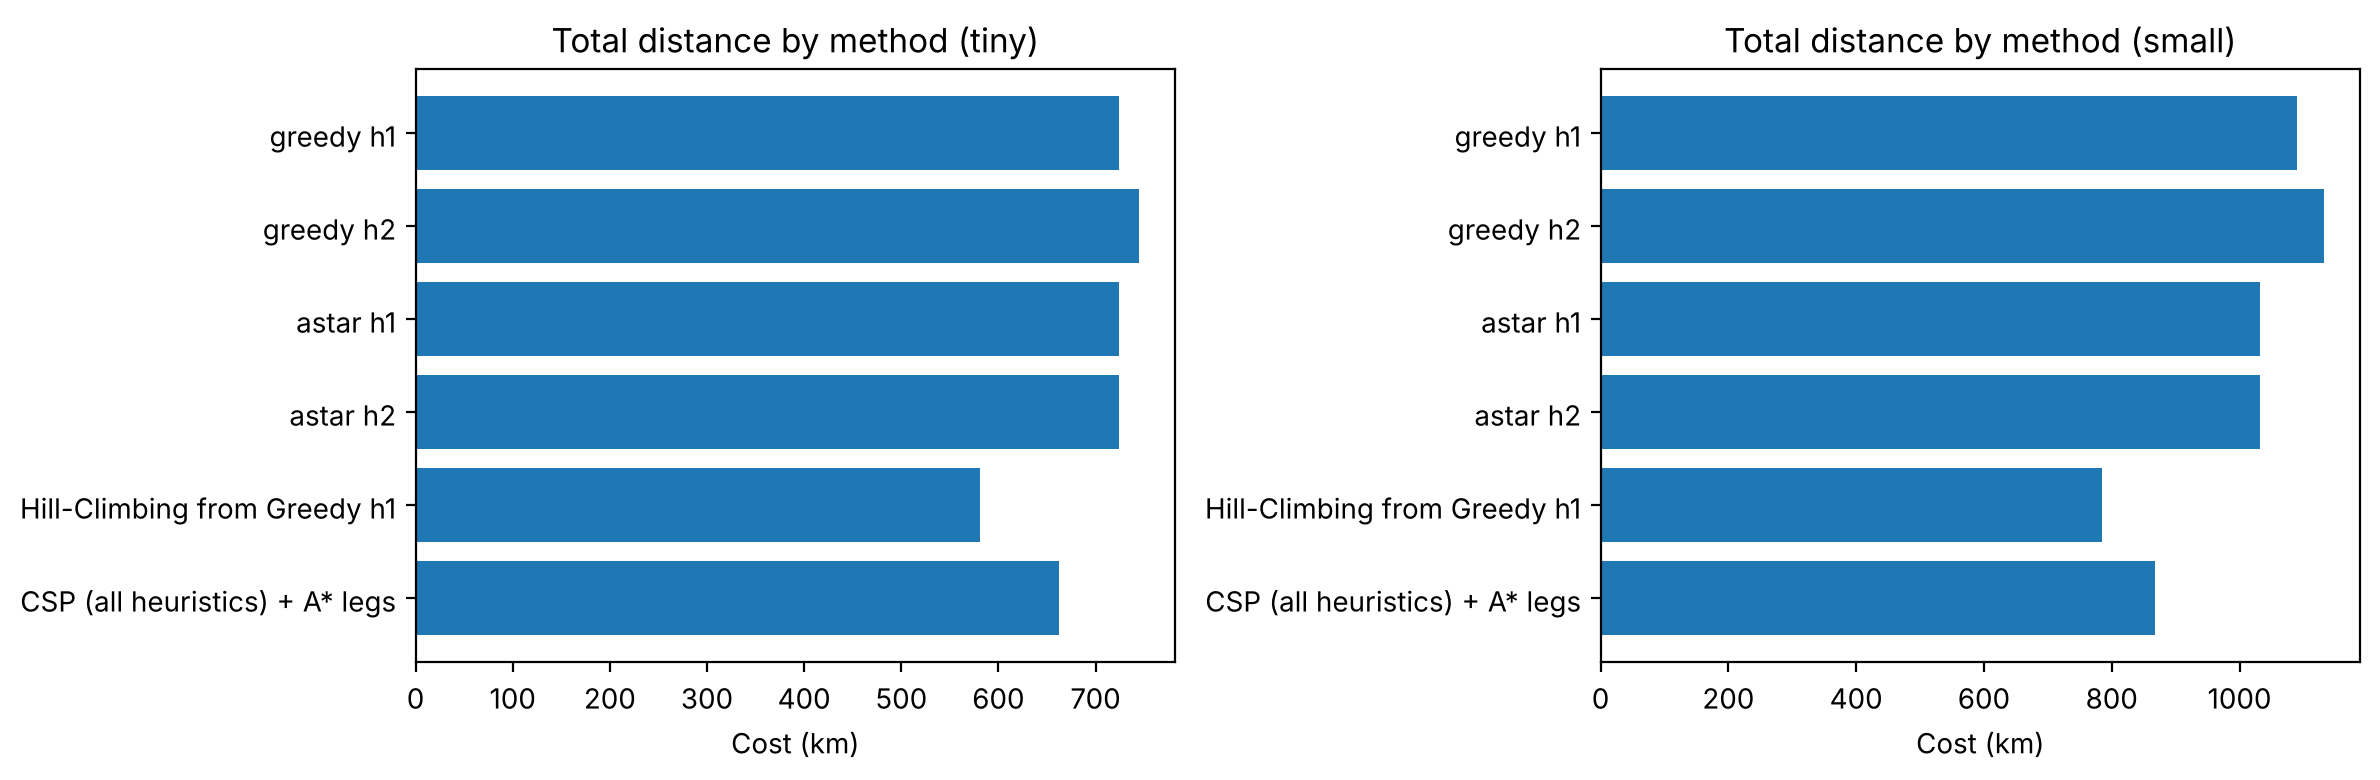

In [26]:
# Cost of every method (tiny and small)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, ["tiny", "small"]):
    part = results[results.dataset == name]
    ax.barh(part.method, part.cost_km, color="tab:blue")
    ax.set_title("Total distance by method (%s)" % name)
    ax.set_xlabel("Cost (km)")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

### Comparison

| Dataset | Best -> worst (cost in km) |
|---|---|
| tiny | Hill-Climbing 580.90 < CSP + A* 662.47 < A* / Greedy h1 724.28 < Greedy h2 744.59 |
| small | Hill-Climbing 785.50 < CSP + A* 867.50 < A* 1031.75 < Greedy h1 1090.63 < Greedy h2 1131.96 |

* All the solutions are **feasible** according to the independent checker.
* **Hill-Climbing is the cheapest in km** because it is the only method that changes the vehicle assignment while looking at the cost. A* and Greedy only order the stops of a fixed split; the CSP finds *a* valid assignment but does not minimise the cost.
* **Time:** informed search takes milliseconds, the CSP about 0.2 s on small, and Hill-Climbing about 0.5 s on tiny and about 9 s on small. The better routes cost more computing time.
* **Caveats.** Each number comes from one deterministic run (fixed seed in the split). Hill-Climbing ends in a local optimum, so 580.90 km and 785.50 km are upper bounds of the optimum, not proofs of optimality. Times depend on the machine.

# 6. Conclusion

* We modelled the pickup-and-delivery problem with the flow producer > warehouse > customer, time windows (with waiting), service and handling times, vehicle capacity and the 24 h dwell limit, and wrote a checker that is independent of the algorithms. It accepts the solutions found and rejects hand-made wrong routes (tests in section 3).
* **Informed search** solved every leg: A* returned the best order of each list (confirmed by brute force on tiny) and `h2` expanded fewer nodes than `h1`; Greedy was cheaper to run but worse with `h2`.
* **Hill-Climbing** from the Greedy solution reduced the distance by 19.8 % (tiny) and 28.0 % (small), mainly by moving stops between vehicles.
* The **CSP** gave feasible assignments on both datasets. Forward checking reduced the backtracks on small, MRV did not help, and AC-3 pruned nothing because the binary constraints are weak.
* **Limitations.** Several interpretations of the brief are our own decisions (section 3.1) and should be confirmed with the lecturer; refrigeration is only a soft preference because the data has no product rule; a vehicle makes at most one collection leg and one delivery leg per kind each day; the moves 2-opt, swap and relocate and the heuristics `h1` and `h2` are our own choices (the slides do not define them for this problem); consistency of the heuristics is not proven; Hill-Climbing gets slow as the dataset grows.
* **Possible improvements.** Optimise the first vehicle split, try random restarts or simulated annealing in the local search, and add a conflict-directed backjumping to the CSP.